# 04 · Customer Segmentation
Two complementary views:

1. **Business-rule segments** (age band × job group) — transparent and easy to explain to a marketing team.
2. **Data-driven segments** (K-Means clustering on customer profile + relationship history) — discovers groups we did not think of.

Only attributes known **before** the call are used. Campaign-execution fields (month, contact channel, calls made) and macro-economic fields are excluded from clustering, so segments describe *who the customer is*, not *how we reached them*; conversion rate is then used to evaluate the segments.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path

ROOT = Path("..")
FIG, TAB = ROOT / "outputs/figures", ROOT / "outputs/tables"
FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)

NAVY, TEAL, ORANGE, GREY = "#1F3A5F", "#2A9D8F", "#E76F51", "#9AA5B1"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.labelsize": 10, "font.size": 10})
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 140)

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
df = pd.read_csv(ROOT / "data/bank_marketing_clean.csv"); BASE = df.subscribed.mean()

## 1. Rule-based segments: age band × job group

In [2]:
seg = (df.groupby(["age_band", "job_group"]).subscribed.agg(customers="size", subscribers="sum", conversion_rate="mean").reset_index())
seg["lift"] = seg.conversion_rate / BASE
seg = seg[seg.customers >= 150].sort_values("conversion_rate", ascending=False)
seg.round(4).to_csv(TAB / "04_rule_based_segments.csv", index=False)
print("Top 8 segments (min 150 customers)"); display(seg.head(8).round(3))
print("Bottom 5"); display(seg.tail(5).round(3))

Top 8 segments (min 150 customers)


,age_band,job_group,customers,subscribers,conversion_rate,lift
29,65+,Retired,559,264,0.472,4.192
37,<25,Student,378,143,0.378,3.358
4,25-34,Student,433,121,0.279,2.480
34,<25,Office & professional,285,59,0.207,1.837
23,55-64,Retired,877,150,0.171,1.518
5,25-34,Unemployed,327,53,0.162,1.439
22,55-64,Office & professional,1356,201,0.148,1.316
1,25-34,Office & professional,7537,1005,0.133,1.184


Bottom 5


,age_band,job_group,customers,subscribers,conversion_rate,lift
21,55-64,Blue-collar & services,929,79,0.085,0.755
16,45-54,Retired,224,16,0.071,0.634
17,45-54,Self-employed,737,51,0.069,0.614
14,45-54,Blue-collar & services,3394,229,0.067,0.599
7,35-44,Blue-collar & services,5046,310,0.061,0.545


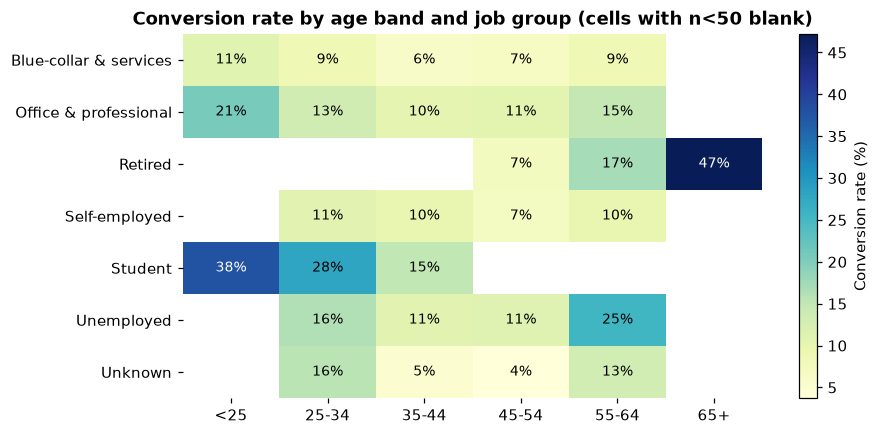

In [3]:
piv = df.pivot_table(index="job_group", columns="age_band", values="subscribed", aggfunc="mean")[["<25", "25-34", "35-44", "45-54", "55-64", "65+"]] * 100
cnt = df.pivot_table(index="job_group", columns="age_band", values="subscribed", aggfunc="size")[piv.columns]
piv = piv.where(cnt >= 50)
fig, ax = plt.subplots(figsize=(8.5, 4.3)); im = ax.imshow(piv, cmap="YlGnBu", aspect="auto")
ax.set_xticks(range(piv.shape[1])); ax.set_xticklabels(piv.columns); ax.set_yticks(range(piv.shape[0])); ax.set_yticklabels(piv.index)
for i in range(piv.shape[0]):
    for j in range(piv.shape[1]):
        v = piv.iloc[i, j]
        if pd.notna(v): ax.text(j, i, f"{v:.0f}%", ha="center", va="center", color="white" if v > 28 else "black", fontsize=9)
fig.colorbar(im, label="Conversion rate (%)"); ax.set_title("Conversion rate by age band and job group (cells with n<50 blank)")
ax.spines[:].set_visible(False); fig.savefig(FIG / "04_heatmap_age_job.png"); plt.show()

## 2. Data-driven segments: K-Means

In [4]:
cat = ["job_group", "marital", "education", "default", "housing", "loan", "poutcome"]
numf = ["age", "previous", "prev_contacted"]
X = pd.get_dummies(df[cat], dtype=float)
Xn = pd.DataFrame(StandardScaler().fit_transform(df[numf]), columns=numf)
Xall = pd.concat([Xn, X], axis=1)
print("Feature matrix:", Xall.shape)

Feature matrix: (41176, 34)


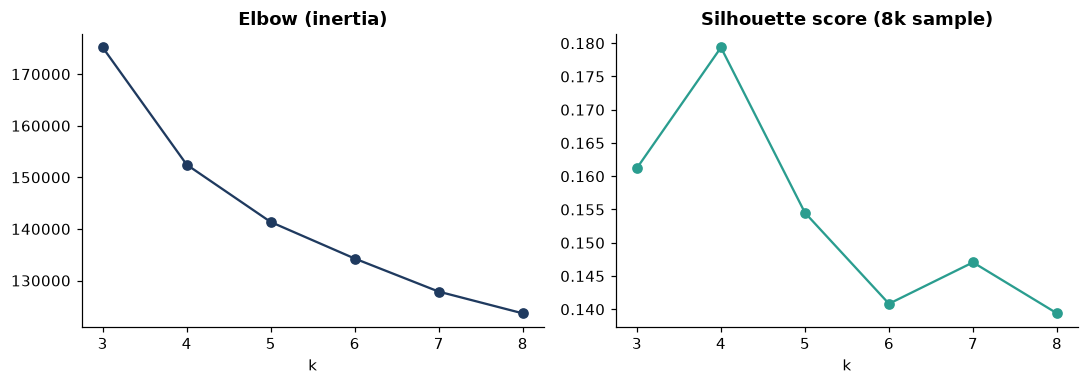

,k,inertia,silhouette
0,3,175163.529,0.161
1,4,152451.948,0.179
2,5,141346.015,0.155
3,6,134264.123,0.141
4,7,127857.492,0.147
5,8,123647.972,0.139


In [5]:
rng = np.random.RandomState(42); idx = rng.choice(len(Xall), 8000, replace=False)
res = []
for k in range(3, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Xall)
    res.append({"k": k, "inertia": km.inertia_, "silhouette": silhouette_score(Xall.iloc[idx], km.labels_[idx])})
sel = pd.DataFrame(res); sel.round(4).to_csv(TAB / "04_kmeans_selection.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].plot(sel.k, sel.inertia, marker="o", color=NAVY); axes[0].set_title("Elbow (inertia)"); axes[0].set_xlabel("k")
axes[1].plot(sel.k, sel.silhouette, marker="o", color=TEAL); axes[1].set_title("Silhouette score (8k sample)"); axes[1].set_xlabel("k")
fig.tight_layout(); fig.savefig(FIG / "04_kmeans_selection.png"); plt.show(); sel.round(3)

In [6]:
K = 4
km = KMeans(n_clusters=K, n_init=20, random_state=42).fit(Xall)
df["cluster"] = km.labels_
prof = df.groupby("cluster").agg(customers=("age", "size"), avg_age=("age", "mean"),
        pct_prev_contacted=("prev_contacted", "mean"), pct_prev_success=("poutcome", lambda s: (s == "success").mean()),
        pct_housing=("housing", lambda s: (s == "yes").mean()), pct_loan=("loan", lambda s: (s == "yes").mean()),
        pct_default_unknown=("default", lambda s: (s == "unknown").mean()),
        top_job_group=("job_group", lambda s: s.mode()[0]), top_education=("education", lambda s: s.mode()[0]),
        top_marital=("marital", lambda s: s.mode()[0]), conversion_rate=("subscribed", "mean"))
prof["share_of_customers"] = prof.customers / len(df); prof["lift"] = prof.conversion_rate / BASE
prof["share_of_subscribers"] = df.groupby("cluster").subscribed.sum() / df.subscribed.sum()
prof.round(3)

,customers,avg_age,pct_prev_contacted,pct_prev_success,pct_housing,pct_loan,pct_default_unknown,top_job_group,top_education,top_marital,conversion_rate,share_of_customers,lift,share_of_subscribers
cluster,,,,,,,,,,,,,,
0,20990,33.171,0.0,0.000,0.520,0.154,0.125,Office & professional,university.degree,married,0.093,0.510,0.829,0.423
1,1515,41.853,1.0,0.906,0.551,0.152,0.042,Office & professional,university.degree,married,0.638,0.037,5.665,0.208
2,14592,49.800,0.0,0.000,0.518,0.149,0.370,Blue-collar & services,university.degree,married,0.082,0.354,0.726,0.257
3,4079,39.633,0.0,0.000,0.556,0.151,0.124,Office & professional,university.degree,married,0.127,0.099,1.127,0.112


### Name the segments

In [7]:
NAMES = {1: 'Past-campaign responders', 3: 'Past-campaign non-responders', 0: 'Young first-time prospects', 2: 'Mature first-time prospects'}
df["segment"] = df.cluster.map(NAMES) if NAMES else df.cluster.astype(str)
prof.insert(0, "segment", [NAMES.get(i, str(i)) for i in prof.index])
prof = prof.sort_values("conversion_rate", ascending=False)
prof.round(4).to_csv(TAB / "04_cluster_profiles.csv")
prof[["segment", "customers", "share_of_customers", "avg_age", "top_job_group", "pct_prev_contacted", "conversion_rate", "lift", "share_of_subscribers"]].round(3)

,segment,customers,share_of_customers,avg_age,top_job_group,pct_prev_contacted,conversion_rate,lift,share_of_subscribers
cluster,,,,,,,,,
1,Past-campaign responders,1515,0.037,41.853,Office & professional,1.0,0.638,5.665,0.208
3,Past-campaign non-responders,4079,0.099,39.633,Office & professional,0.0,0.127,1.127,0.112
0,Young first-time prospects,20990,0.510,33.171,Office & professional,0.0,0.093,0.829,0.423
2,Mature first-time prospects,14592,0.354,49.800,Blue-collar & services,0.0,0.082,0.726,0.257


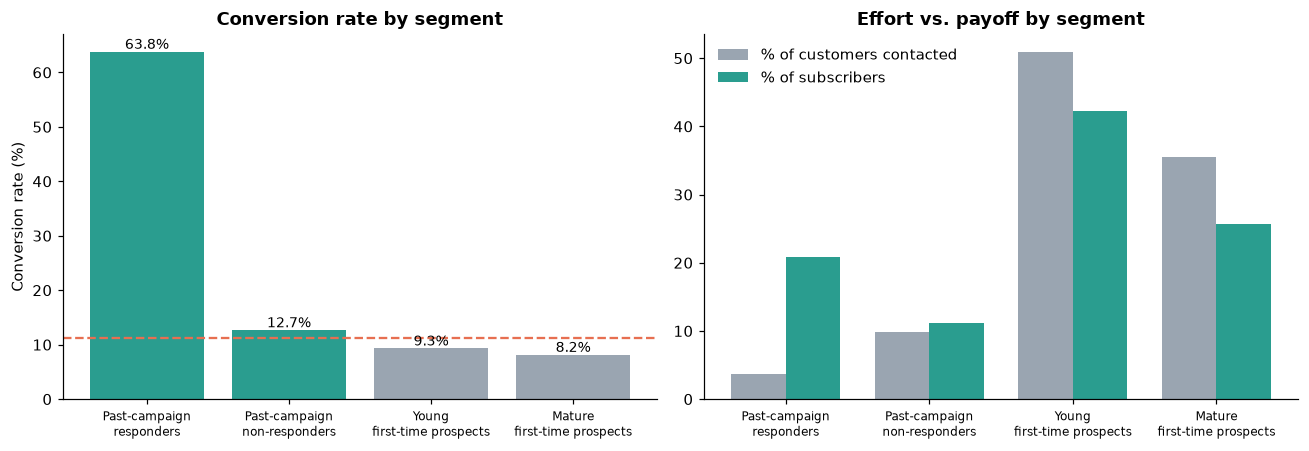

In [8]:
order = prof.index
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
lab = prof.segment.str.replace(" ", "\n", n=1)
axes[0].bar(lab, prof.conversion_rate * 100, color=[TEAL if r > BASE else GREY for r in prof.conversion_rate])
axes[0].axhline(BASE * 100, color=ORANGE, ls="--"); axes[0].set_ylabel("Conversion rate (%)"); axes[0].set_title("Conversion rate by segment")
for i, v in enumerate(prof.conversion_rate * 100): axes[0].text(i, v + .5, f"{v:.1f}%", ha="center", fontsize=9)
w = .38; x = np.arange(len(prof))
axes[1].bar(x - w/2, prof.share_of_customers * 100, w, color=GREY, label="% of customers contacted")
axes[1].bar(x + w/2, prof.share_of_subscribers * 100, w, color=TEAL, label="% of subscribers")
axes[1].set_xticks(x); axes[1].set_xticklabels(lab, fontsize=8); axes[1].legend(frameon=False); axes[1].set_title("Effort vs. payoff by segment")
for a in axes: a.tick_params(axis="x", labelsize=8)
fig.tight_layout(); fig.savefig(FIG / "04_segment_conversion.png"); plt.show()

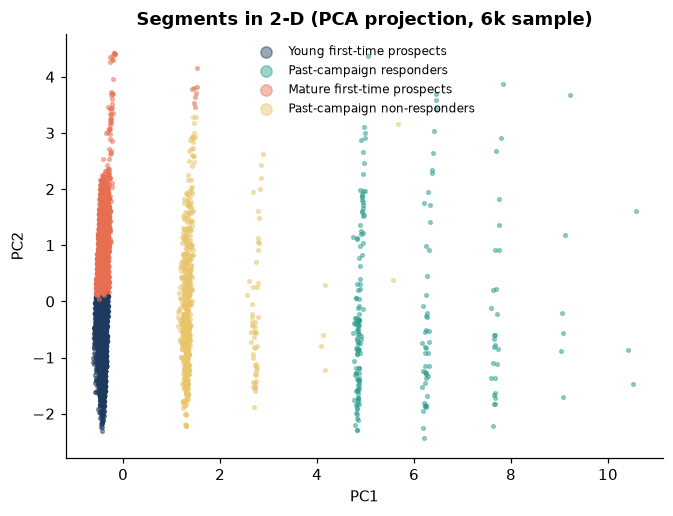

In [9]:
from sklearn.decomposition import PCA
p = PCA(2, random_state=42).fit_transform(Xall); s = rng.choice(len(p), 6000, replace=False)
fig, ax = plt.subplots(figsize=(7, 5)); pal = [NAVY, TEAL, ORANGE, "#E9C46A", "#8E6BBF", "#6C757D", "#C44569", "#4A90A4"]
for i, cl in enumerate(sorted(df.cluster.unique())):
    m = df.cluster.values[s] == cl; ax.scatter(p[s][m, 0], p[s][m, 1], s=6, alpha=.45, color=pal[i], label=NAMES.get(cl, str(cl)))
ax.legend(markerscale=3, frameon=False, fontsize=8); ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_title("Segments in 2-D (PCA projection, 6k sample)")
fig.savefig(FIG / "04_segments_pca.png"); plt.show()

## 3. Which segments should the bank prioritise? (value vs. volume)

In [10]:
q = prof[["segment", "customers", "conversion_rate", "lift", "share_of_customers", "share_of_subscribers"]].copy()
q["subscribers"] = (q.customers * q.conversion_rate).round().astype(int)
q["priority"] = np.where(q.lift >= 1.5, "Protect & prioritise", np.where(q.lift >= 0.9, "Maintain", "Reduce / re-target"))
q.round(3).to_csv(TAB / "04_segment_priority.csv", index=False); q.round(3)

,segment,customers,conversion_rate,lift,share_of_customers,share_of_subscribers,subscribers,priority
cluster,,,,,,,,
1,Past-campaign responders,1515,0.638,5.665,0.037,0.208,967,Protect & prioritise
3,Past-campaign non-responders,4079,0.127,1.127,0.099,0.112,518,Maintain
0,Young first-time prospects,20990,0.093,0.829,0.510,0.423,1961,Reduce / re-target
2,Mature first-time prospects,14592,0.082,0.726,0.354,0.257,1193,Reduce / re-target


In [11]:
df.to_csv(ROOT / "data/bank_marketing_clean.csv", index=False)   # keep cluster labels alongside the clean data
print("Saved cluster labels back to data/bank_marketing_clean.csv")

Saved cluster labels back to data/bank_marketing_clean.csv


## Key findings
* **k = 4** was chosen because it has the highest silhouette score (0.179). Scores are modest, so segments are overlapping profiles rather than sharply separated groups. Prior-campaign history is the dominant separator.
* **Past-campaign responders** are just **3.7% of customers but 20.8% of all subscribers** (63.8% conversion, 5.7x lift) — the clearest "protect & prioritise" group.
* **Past non-responders** (9.9% of customers) still convert at 12.7%, slightly above average — worth a re-approach with a new offer.
* **First-time prospects** (86% of the base) convert at only 8-9%; younger prospects (avg. age 33) do slightly better than older (avg. 50) ones, who also have more "unknown" credit-default records.
* Rule-based view: **retired 65+ (47.2%)**, **under-25 students (37.8%)** and **25-34 students (27.9%)** are the best demographic pockets, but they are small.